# 01 - Exploratory Data Analysis (CIC-IDS2017, Friday)

Goal: understand the data before modelling.

1. How many flows of each class are there? (class imbalance)
2. What data-quality problems exist? (inf/NaN, duplicates, useless columns)
3. Do the classes look different on a few key features?
4. How redundant are the features? (motivates feature selection later)

At the end we save a cleaned copy to `data/processed/` for the next notebooks.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))  # so `src` can be imported from notebooks/
from src.data import load_friday, clean, feature_columns, LABEL_COL, PROCESSED_DIR, FIGURES_DIR

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

## 1. Load the three Friday files

In [2]:
raw = load_friday()
print("Shape:", raw.shape)
print(f"Memory: {raw.memory_usage(deep=True).sum() / 1e6:.0f} MB")
raw.head()

Shape: (703245, 80)
Memory: 465 MB


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file
0,3268,112740690,32,16,6448,1152,403,0,201.5,204.724205,72,72,72.0,0.0,67.411331,0.425756,2.398738e+06,5.798698e+06,16400000,3,113000000,3.636796e+06,6.848761e+06,16400000,3,113000000,7516023.200,8323384.915,16400000,3,1,0,0,0,1024,512,0.283837,0.141919,0,403,163.326531,178.931713,32016.55782,0,1,0,0,1,0,0,0,0,166.729167,201.5,72.0,1024,0,0,0,0,0,0,32,6448,16,1152,377,2079,15,32,3.594286e+02,1.199802e+01,380,343,16100000.0,4.988048e+05,16400000,15400000,BENIGN,morning_bot
1,389,112740560,32,16,6448,5056,403,0,201.5,204.724205,316,316,316.0,0.0,102.039585,0.425756,2.398735e+06,5.798710e+06,16400000,2,113000000,3.636792e+06,6.848777e+06,16400000,2,113000000,7516016.133,8323376.147,16400000,4,1,0,0,0,1024,512,0.283838,0.141919,0,403,243.000000,174.716914,30526.00000,0,1,0,0,1,0,0,0,0,248.062500,201.5,316.0,1024,0,0,0,0,0,0,32,6448,16,5056,955,2079,15,32,3.202857e+02,1.574499e+01,330,285,16100000.0,4.987937e+05,16400000,15400000,BENIGN,morning_bot
2,0,113757377,545,0,0,0,0,0,0.0,0.000000,0,0,0.0,0.0,0.000000,4.790898,2.091128e+05,1.395543e+06,20800000,0,114000000,2.091128e+05,1.395543e+06,20800000,0,0,0.000,0.000,0,0,0,0,0,0,0,0,4.790898,0.000000,0,0,0.000000,0.000000,0.00000,0,0,0,0,0,0,0,0,0,0.000000,0.0,0.0,0,0,0,0,0,0,0,545,0,0,0,-1,-1,0,0,9.361829e+06,7.324646e+06,18900000,19,12200000.0,6.935824e+06,20800000,5504997,BENIGN,morning_bot
3,5355,100126,22,0,616,0,28,28,28.0,0.000000,0,0,0.0,0.0,6152.248167,219.723149,4.767905e+03,2.183302e+04,100055,1,100126,4.767905e+03,2.183302e+04,100055,1,0,0.000,0.000,0,0,0,0,0,0,704,0,219.723149,0.000000,28,28,28.000000,0.000000,0.00000,0,0,0,0,0,0,0,0,0,29.272727,28.0,0.0,704,0,0,0,0,0,0,22,616,0,0,-1,-1,21,32,0.000000e+00,0.000000e+00,0,0,0.0,0.000000e+00,0,0,BENIGN,morning_bot
4,0,54760,4,0,0,0,0,0,0.0,0.000000,0,0,0.0,0.0,0.000000,73.046019,1.825333e+04,3.046984e+04,53431,108,54760,1.825333e+04,3.046984e+04,53431,108,0,0.000,0.000,0,0,0,0,0,0,0,0,73.046019,0.000000,0,0,0.000000,0.000000,0.00000,0,0,0,0,0,0,0,0,0,0.000000,0.0,0.0,0,0,0,0,0,0,0,4,0,0,0,-1,-1,0,0,0.000000e+00,0.000000e+00,0,0,0.0,0.000000e+00,0,0,BENIGN,morning_bot


In [3]:
raw.dtypes.value_counts()

int64      54
float64    24
str         2
Name: count, dtype: int64

## 2. Class distribution

This is the most important table in the notebook: it tells us whether plain
accuracy is a meaningful metric.

In [4]:
counts = raw[LABEL_COL].value_counts()
dist = pd.DataFrame({"count": counts, "percent": (100 * counts / counts.sum()).round(3)})
dist

,count,percent
Label,,
BENIGN,414322,58.916
PortScan,158930,22.600
DDoS,128027,18.205
Bot,1966,0.280


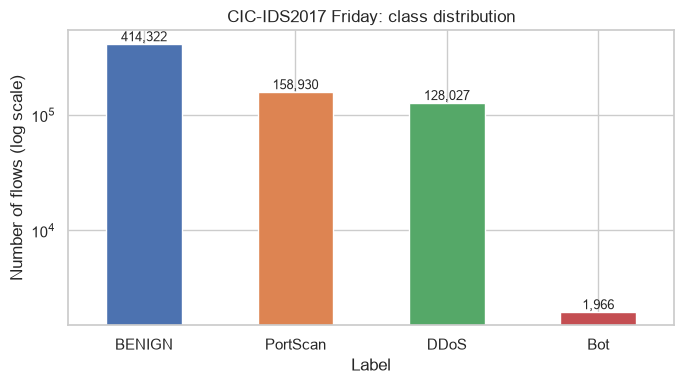

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
counts.plot.bar(ax=ax, color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"][: len(counts)])
ax.set_yscale("log")
ax.set_ylabel("Number of flows (log scale)")
ax.set_title("CIC-IDS2017 Friday: class distribution")
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "class_distribution.png", dpi=150)
plt.show()

Which capture does each label come from?

In [6]:
pd.crosstab(raw["source_file"], raw[LABEL_COL])

Label,BENIGN,Bot,DDoS,PortScan
source_file,,,,
afternoon_ddos,97718,0,128027,0
afternoon_portscan,127537,0,0,158930
morning_bot,189067,1966,0,0


## 3. Data-quality checks

In [7]:
feats = feature_columns(raw)
num = raw[feats]

inf_counts = np.isinf(num).sum()
nan_counts = num.isna().sum()
quality = pd.DataFrame({"inf": inf_counts, "nan": nan_counts})
quality[(quality["inf"] > 0) | (quality["nan"] > 0)]

,inf,nan
Flow Bytes/s,480,47
Flow Packets/s,527,0


In [8]:
if "Fwd Header Length.1" in raw.columns:
    same = raw["Fwd Header Length"].equals(raw["Fwd Header Length.1"])
    print("'Fwd Header Length.1' identical to 'Fwd Header Length':", same)

constant_cols = [c for c in feats if raw[c].nunique() <= 1]
print(f"Constant columns ({len(constant_cols)}):", constant_cols)

dup = raw.duplicated(subset=feats + [LABEL_COL]).sum()
print(f"Duplicate rows: {dup:,} ({100 * dup / len(raw):.1f}%)")

'Fwd Header Length.1' identical to 'Fwd Header Length': True


Constant columns (10): ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


Duplicate rows: 87,351 (12.4%)


In [9]:
# Negative values in features that should be counts/durations are a known CIC-IDS2017 quirk.
neg = (num < 0).sum()
neg[neg > 0].sort_values(ascending=False)

Init_Win_bytes_backward    283660
Init_Win_bytes_forward     188969
Flow IAT Min                  509
Flow Duration                  47
Flow Packets/s                 47
Flow IAT Mean                  47
Flow IAT Max                   47
Flow Bytes/s                   46
Fwd IAT Min                     6
dtype: int64

## 4. Clean

All fixes live in `src/data.py::clean` so every notebook uses exactly the same data.

In [10]:
df, report = clean(raw)
for k, v in report.items():
    print(f"{k}: {v}")

rows_before: 703245
cols_before: 80
rows_with_nan_or_inf: 527
dropped_columns: ['Fwd Header Length.1', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
duplicate_rows_removed: 87285
rows_after: 615433
cols_after: 69


In [11]:
after = df[LABEL_COL].value_counts()
pd.DataFrame({"before": counts, "after": after, "removed": counts - after})

,before,after,removed
Label,,,
BENIGN,414322,394777,19545
Bot,1966,1948,18
DDoS,128027,128014,13
PortScan,158930,90694,68236


## 5. Do the classes look different?

Box plots of a few features per class (log scale, on a sample for speed).
If the boxes barely overlap, even a simple model will separate the classes.

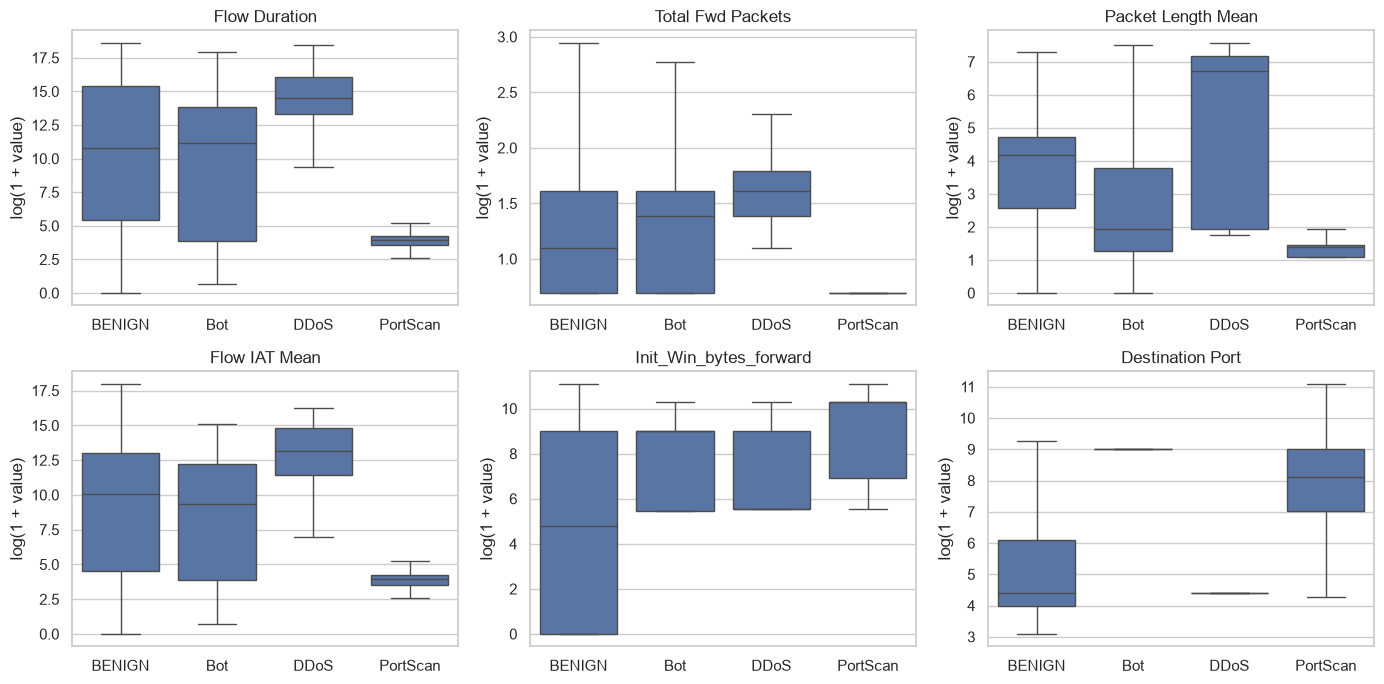

In [12]:
show = [c for c in ["Flow Duration", "Total Fwd Packets", "Packet Length Mean",
                    "Flow IAT Mean", "Init_Win_bytes_forward", "Destination Port"]
        if c in df.columns]

sample = pd.concat(
    g.sample(min(len(g), 5000), random_state=42) for _, g in df.groupby(LABEL_COL)
)
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, show):
    sns.boxplot(data=sample, x=LABEL_COL, y=np.log1p(sample[col].clip(lower=0)), ax=ax,
                showfliers=False)
    ax.set_title(col)
    ax.set_ylabel("log(1 + value)")
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "feature_boxplots.png", dpi=150)
plt.show()

**Note on `Destination Port`:** it can be a very strong but misleading feature
(a model may learn "port 8080 = Bot" instead of learning bot *behaviour*).
We will compare results with and without it in notebook 03.

## 6. Feature redundancy

Many CIC-IDS2017 features are near-copies of each other (e.g. a mean and a sum of
the same packets). Counting highly correlated pairs shows how much room there is
for feature selection.

In [13]:
feats = feature_columns(df)
corr = df[feats].sample(min(len(df), 100_000), random_state=42).corr().abs()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().sort_values(ascending=False)
print(f"{len(feats)} features, {(pairs > 0.95).sum()} pairs with |r| > 0.95")
pairs.head(15)

67 features, 60 pairs with |r| > 0.95


Fwd Packet Length Mean       Avg Fwd Segment Size      1.000000
Bwd Packet Length Mean       Avg Bwd Segment Size      1.000000
Fwd PSH Flags                SYN Flag Count            1.000000
Total Backward Packets       Subflow Bwd Packets       1.000000
RST Flag Count               ECE Flag Count            1.000000
Total Fwd Packets            Subflow Fwd Packets       1.000000
Total Length of Fwd Packets  Subflow Fwd Bytes         1.000000
Total Length of Bwd Packets  Subflow Bwd Bytes         1.000000
Total Backward Packets       Subflow Fwd Packets       0.999721
Total Fwd Packets            Total Backward Packets    0.999721
                             Subflow Bwd Packets       0.999721
Subflow Fwd Packets          Subflow Bwd Packets       0.999721
Fwd Header Length            Bwd Header Length         0.999370
Total Length of Bwd Packets  Fwd Header Length         0.999074
Fwd Header Length            Subflow Bwd Bytes         0.999069
dtype: float64

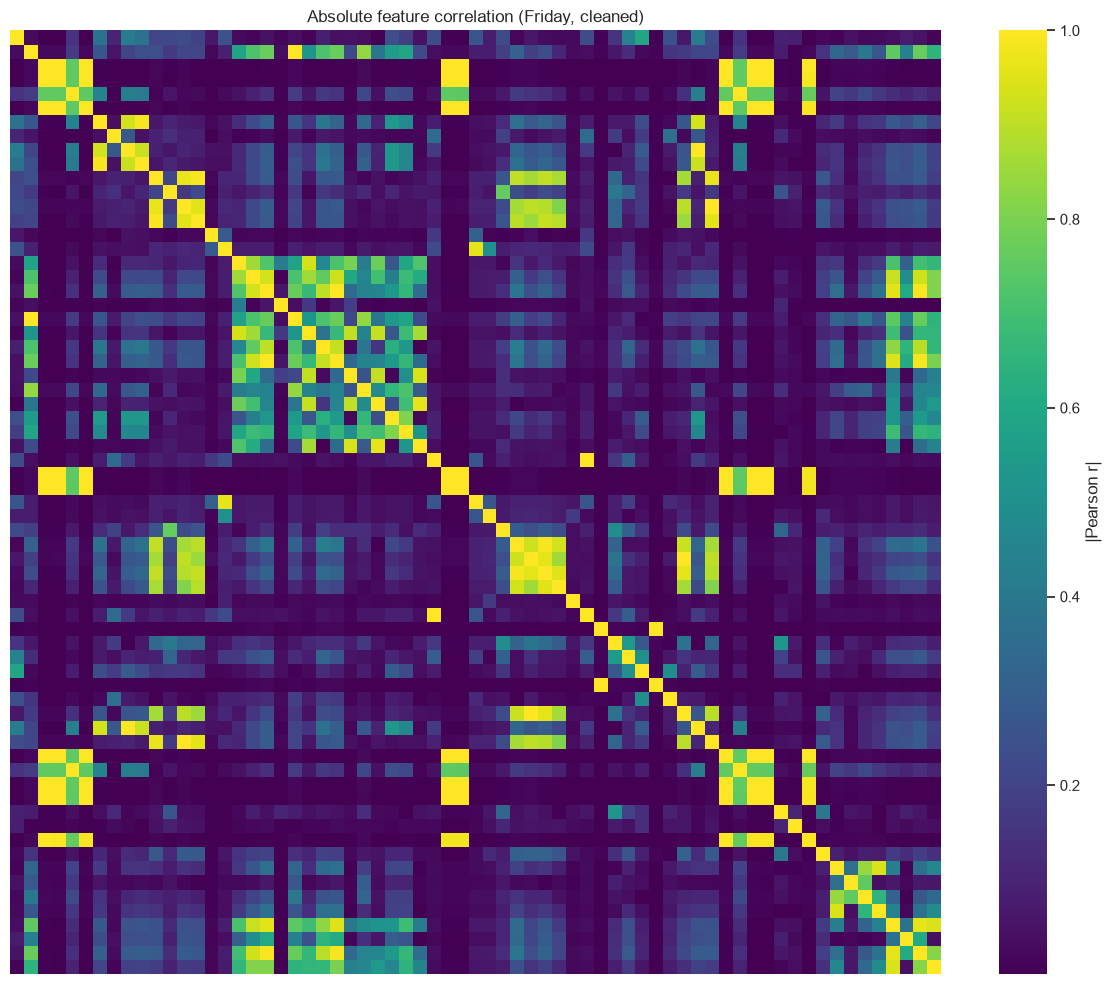

In [14]:
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="viridis", ax=ax, xticklabels=False, yticklabels=False,
            cbar_kws={"label": "|Pearson r|"})
ax.set_title("Absolute feature correlation (Friday, cleaned)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "correlation_heatmap.png", dpi=150)
plt.show()

## 7. Save the cleaned data

In [15]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
out = PROCESSED_DIR / "friday_clean.parquet"
df.to_parquet(out, index=False)
print("Saved", out, df.shape)

Saved C:\Users\ohmah\OneDrive - Universiti Teknologi Malaysia (UTM)\Desktop\IDS\data\processed\friday_clean.parquet (615433, 69)


## 8. Observations (fill in after running)

- Class balance: ...
- Data quality: ...
- Separability: ...
- Redundancy: ...